In [1]:
import os
import pandas as pd
import numpy as np
import sklearn

print("===== ENVIRONMENT =====")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\n===== AVAILABLE CSV FILES =====")

csv_files = [f for f in os.listdir() if f.lower().endswith(".csv")]

for file in csv_files:
    print(file)

print("\nTotal CSV files found:", len(csv_files))

===== ENVIRONMENT =====
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1

===== AVAILABLE CSV FILES =====
beauty_clean.csv
beauty_preprocessed.csv
customer_features_preprocessed.csv
customer_features_scaled.csv
week4_business_insights.csv
week4_category_risk_analysis.csv
week4_customer_features.csv
week4_market_risk_analysis.csv
week4_transaction_features.csv

Total CSV files found: 9


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("beauty_clean.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())
print("\nData types:")
print(df.dtypes)

Shape: (51290, 19)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Customer ID', 'Segment', 'City', 'State', 'Country', 'Country latitude', 'Country longitude', 'Region', 'Market', 'Subcategory', 'Category', 'Product', 'Quantity', 'Sales', 'Discount', 'Profit']

First 5 rows:


,Row ID,Order ID,Order Date,Customer ID,Segment,City,State,Country,Country latitude,Country longitude,Region,Market,Subcategory,Category,Product,Quantity,Sales,Discount,Profit
0,25221,IN-2012-TH211151-41003,2020-04-04,TH-211151,Corporate,Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific,"bath oils, bubbles and soaks",Body care,Soap & Glory Endless Glove Moisturizing Hand C...,13,416,0.0,208.0
1,25220,IN-2012-TH211151-41003,2020-04-04,TH-211151,Corporate,Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific,hand creams,Body care,MAC ColorStay Foundation,5,70,0.0,35.0
2,25218,IN-2012-TH211151-41003,2020-04-04,TH-211151,Corporate,Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific,Nail care products,Body care,Eucerin Advanced Repair Cream,18,216,0.0,108.0
3,25217,IN-2012-TH211151-41003,2020-04-04,TH-211151,Corporate,Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific,"candles, sprays, diffusers",Home and Accessories,Diptyque French Cade Lavender Candle,12,132,0.0,13.2
4,25219,IN-2012-TH211151-41003,2020-04-04,TH-211151,Corporate,Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific,Eye shadows and pencils,Make up,NARS Single Eyeshadow Persia Matte Paprika,2,34,0.0,17.0



Data types:
Row ID                 int64
Order ID              object
Order Date            object
Customer ID           object
Segment               object
City                  object
State                 object
Country               object
Country latitude     float64
Country longitude    float64
Region                object
Market                object
Subcategory           object
Category              object
Product               object
Quantity               int64
Sales                  int64
Discount             float64
Profit               float64
dtype: object


In [3]:
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

print("Date Range:", df["Order Date"].min(), "to", df["Order Date"].max())
print("Total Transactions:", len(df))
print("Unique Customers:", df["Customer ID"].nunique())
print("Unique Orders:", df["Order ID"].nunique())
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nTransactions by Year:")
print(df["Order Date"].dt.year.value_counts().sort_index())

print("\nCustomer Purchase Summary:")
display(
    df.groupby("Customer ID").agg(
        Total_Transactions=("Order ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        First_Purchase=("Order Date", "min"),
        Last_Purchase=("Order Date", "max")
    ).head()
)

Date Range: 2020-01-01 00:00:00 to 2023-12-31 00:00:00
Total Transactions: 51290
Unique Customers: 17415
Unique Orders: 25728
Missing Values: 0
Duplicate Rows: 0

Transactions by Year:
Order Date
2020     8998
2021    10962
2022    13799
2023    17531
Name: count, dtype: int64

Customer Purchase Summary:


,Total_Transactions,Unique_Orders,First_Purchase,Last_Purchase
Customer ID,,,,
AA-10315102,6,2,2020-07-03,2023-01-07
AA-10315120,1,1,2021-05-16,2021-05-16
AA-10315139,13,4,2022-09-19,2023-08-04
AA-103151402,6,2,2022-03-04,2023-06-30
AA-103151404,3,2,2020-03-30,2021-10-04


In [4]:
cutoff_date = pd.Timestamp("2023-06-30")
future_end_date = cutoff_date + pd.Timedelta(days=90)

historical_data = df[df["Order Date"] <= cutoff_date].copy()

future_data = df[
    (df["Order Date"] > cutoff_date) &
    (df["Order Date"] <= future_end_date)
].copy()

future_purchases = future_data.groupby("Customer ID")["Order ID"].nunique()

historical_customers = historical_data["Customer ID"].unique()

target = pd.DataFrame({"Customer ID": historical_customers})

target["Future_Orders"] = target["Customer ID"].map(future_purchases).fillna(0).astype(int)

target["Churn"] = (target["Future_Orders"] == 0).astype(int)

print("Cutoff Date:", cutoff_date.date())
print("Future Observation End:", future_end_date.date())
print("Historical Transactions:", len(historical_data))
print("Future Transactions:", len(future_data))
print("Customers in Modeling Dataset:", len(target))

print("\nChurn Target Distribution:")
print(target["Churn"].value_counts().rename(index={0: "Retained", 1: "Churned"}))

print("\nChurn Percentage:")
print((target["Churn"].value_counts(normalize=True).sort_index() * 100).rename(index={0: "Retained", 1: "Churned"}).round(2))

Cutoff Date: 2023-06-30
Future Observation End: 2023-09-28
Historical Transactions: 40584
Future Transactions: 4634
Customers in Modeling Dataset: 14716

Churn Target Distribution:
Churn
Churned     13690
Retained     1026
Name: count, dtype: int64

Churn Percentage:
Churn
Retained     6.97
Churned     93.03
Name: proportion, dtype: float64


In [5]:
customer_features = historical_data.groupby("Customer ID").agg(
    Last_Purchase=("Order Date", "max"),
    Total_Transactions=("Order ID", "count"),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Avg_Discount=("Discount", "mean"),
    Avg_Sales=("Sales", "mean"),
    Unique_Categories=("Category", "nunique"),
    Unique_Markets=("Market", "nunique")
).reset_index()

customer_features["Recency"] = (
    cutoff_date - customer_features["Last_Purchase"]
).dt.days

customer_features["Average_Order_Value"] = (
    customer_features["Monetary"] / customer_features["Frequency"]
)

customer_features = customer_features.drop(columns=["Last_Purchase"])

model_data = customer_features.merge(
    target[["Customer ID", "Churn"]],
    on="Customer ID",
    how="inner"
)

print("Feature Dataset Shape:", customer_features.shape)
print("Model Dataset Shape:", model_data.shape)
print("\nMissing Values:", model_data.isnull().sum().sum())
print("Duplicate Customer IDs:", model_data["Customer ID"].duplicated().sum())

print("\nFeature Summary:")
display(model_data.describe().round(2).T)

print("\nChurn Distribution:")
display(model_data["Churn"].value_counts().rename(index={0: "Retained", 1: "Churned"}))

Feature Dataset Shape: (14716, 12)
Model Dataset Shape: (14716, 13)

Missing Values: 0
Duplicate Customer IDs: 0

Feature Summary:


,count,mean,std,min,25%,50%,75%,max
Total_Transactions,14716.0,2.76,2.19,1.0,1.00,2.0,4.00,24.0
Frequency,14716.0,1.38,0.73,1.0,1.00,1.0,2.00,9.0
Monetary,14716.0,353.19,553.19,2.0,60.00,161.0,404.00,6841.0
Total_Profit,14716.0,60.74,178.29,-1989.4,1.60,21.6,78.40,2625.3
Total_Quantity,14716.0,15.01,18.20,1.0,4.00,9.0,18.00,214.0
Avg_Discount,14716.0,0.14,0.20,0.0,0.00,0.0,0.24,0.8
Avg_Sales,14716.0,126.97,189.95,2.0,35.14,70.0,148.00,3820.0
Unique_Categories,14716.0,1.91,1.01,1.0,1.00,2.0,3.00,5.0
Unique_Markets,14716.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
Recency,14716.0,484.55,348.59,0.0,199.00,404.0,741.00,1276.0



Churn Distribution:


Churn
Churned     13690
Retained     1026
Name: count, dtype: int64

In [6]:
from sklearn.model_selection import train_test_split

X = model_data.drop(columns=["Customer ID", "Churn", "Unique_Markets"])
y = model_data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\nFeatures Used:")
print(X.columns.tolist())

Training Features: (11772, 10)
Testing Features: (2944, 10)

Training Target Distribution:
Churn
1    10951
0      821
Name: count, dtype: int64
Churn
1    93.03
0     6.97
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
1    2739
0     205
Name: count, dtype: int64
Churn
1    93.04
0     6.96
Name: proportion, dtype: float64

Features Used:
['Total_Transactions', 'Frequency', 'Monetary', 'Total_Profit', 'Total_Quantity', 'Avg_Discount', 'Avg_Sales', 'Unique_Categories', 'Recency', 'Average_Order_Value']


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))
])

tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=30,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("Logistic Regression training completed.")
print("Decision Tree training completed.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Logistic Regression training completed.
Decision Tree training completed.
Training samples: 11772
Testing samples: 2944


In [8]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1_Score": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities)
    })

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)
    print(classification_report(
        y_test, predictions,
        target_names=["Retained", "Churned"],
        zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

results_df = pd.DataFrame(results).sort_values("F1_Score", ascending=False)

print("\nMODEL COMPARISON")
display(results_df.round(4))


Logistic Regression
              precision    recall  f1-score   support

    Retained       0.10      0.48      0.16       205
     Churned       0.95      0.67      0.78      2739

    accuracy                           0.65      2944
   macro avg       0.52      0.57      0.47      2944
weighted avg       0.89      0.65      0.74      2944

Confusion Matrix:
[[  99  106]
 [ 917 1822]]

Decision Tree
              precision    recall  f1-score   support

    Retained       0.11      0.48      0.18       205
     Churned       0.95      0.72      0.82      2739

    accuracy                           0.70      2944
   macro avg       0.53      0.60      0.50      2944
weighted avg       0.89      0.70      0.77      2944

Confusion Matrix:
[[  98  107]
 [ 765 1974]]

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
1,Decision Tree,0.7038,0.9486,0.7207,0.8191,0.6183,0.9496
0,Logistic Regression,0.6525,0.9450,0.6652,0.7808,0.5863,0.9460


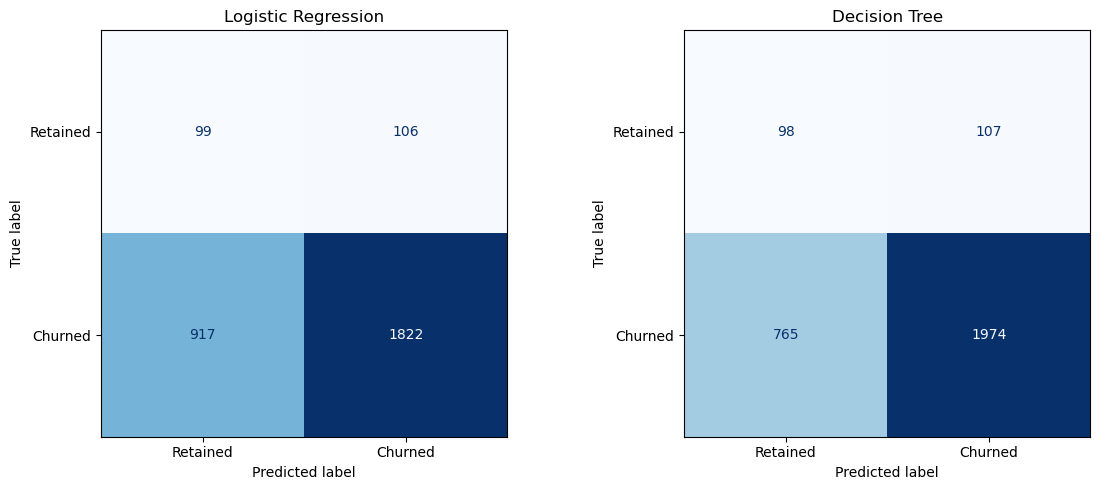

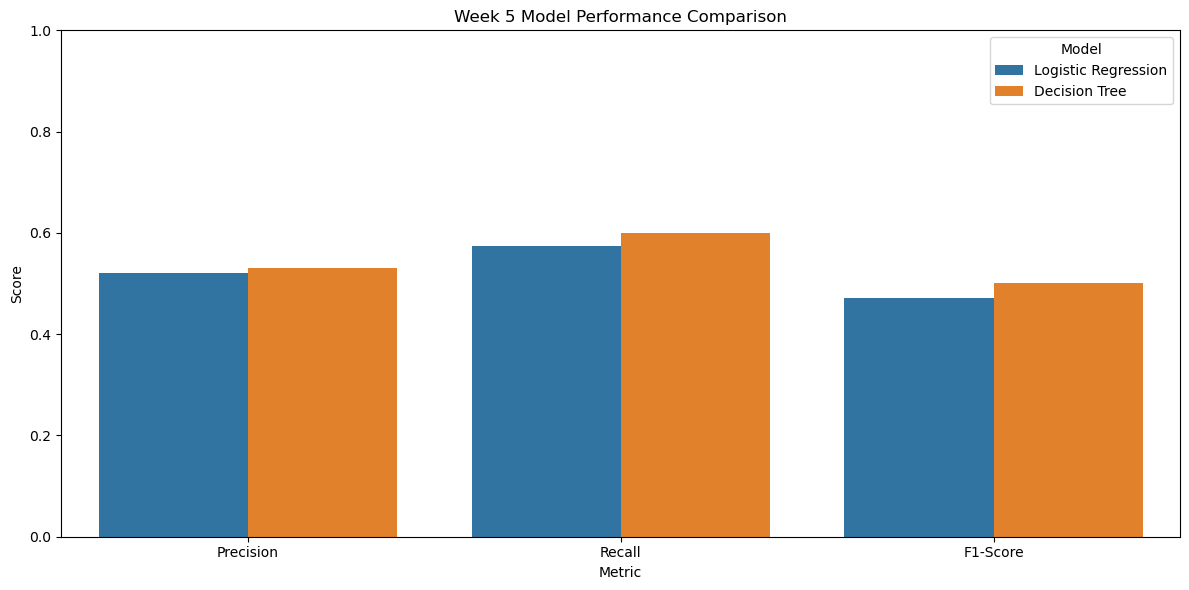

Saved: week5_confusion_matrices.png
Saved: week5_model_performance.png


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    predictions = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Retained", "Churned"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig("week5_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

class_metrics = []

for name, model in models.items():
    predictions = model.predict(X_test)
    report = classification_report(
        y_test, predictions,
        target_names=["Retained", "Churned"],
        output_dict=True,
        zero_division=0
    )

    for label in ["Retained", "Churned"]:
        class_metrics.append({
            "Model": name,
            "Class": label,
            "Precision": report[label]["precision"],
            "Recall": report[label]["recall"],
            "F1-Score": report[label]["f1-score"]
        })

class_metrics_df = pd.DataFrame(class_metrics)

class_metrics_long = class_metrics_df.melt(
    id_vars=["Model", "Class"],
    value_vars=["Precision", "Recall", "F1-Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=class_metrics_long,
    x="Metric",
    y="Score",
    hue="Model",
    errorbar=None
)
plt.ylim(0, 1)
plt.title("Week 5 Model Performance Comparison")
plt.tight_layout()
plt.savefig("week5_model_performance.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: week5_confusion_matrices.png")
print("Saved: week5_model_performance.png")

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Train_F1_Mean": scores["train_f1"].mean(),
        "CV_F1_Mean": scores["test_f1"].mean(),
        "CV_F1_Std": scores["test_f1"].std(),
        "Train_ROC_AUC": scores["train_roc_auc"].mean(),
        "CV_ROC_AUC_Mean": scores["test_roc_auc"].mean(),
        "CV_PR_AUC_Mean": scores["test_average_precision"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print("5-FOLD STRATIFIED CROSS-VALIDATION")
display(cv_results_df.round(4))

5-FOLD STRATIFIED CROSS-VALIDATION


,Model,Train_F1_Mean,CV_F1_Mean,CV_F1_Std,Train_ROC_AUC,CV_ROC_AUC_Mean,CV_PR_AUC_Mean
0,Logistic Regression,0.7836,0.7832,0.0140,0.5878,0.5722,0.9438
1,Decision Tree,0.7909,0.7842,0.0516,0.6748,0.5753,0.9408


DECISION TREE FEATURE IMPORTANCE


,Feature,Importance
5,Avg_Discount,0.4249
1,Frequency,0.2000
8,Recency,0.1016
6,Avg_Sales,0.0969
3,Total_Profit,0.0933
4,Total_Quantity,0.0280
2,Monetary,0.0226
0,Total_Transactions,0.0213
9,Average_Order_Value,0.0115
7,Unique_Categories,0.0000


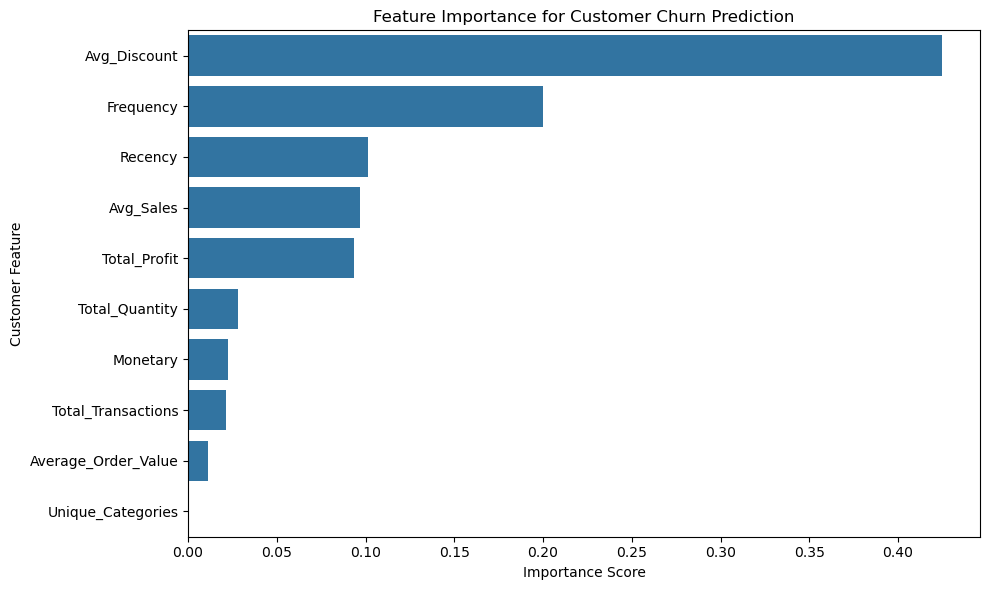

Saved: week5_feature_importance.png
Saved: week5_feature_importance.csv


In [11]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("DECISION TREE FEATURE IMPORTANCE")
display(importance_df.round(4))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    errorbar=None
)
plt.title("Feature Importance for Customer Churn Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Customer Feature")
plt.tight_layout()
plt.savefig("week5_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

importance_df.to_csv("week5_feature_importance.csv", index=False)

print("Saved: week5_feature_importance.png")
print("Saved: week5_feature_importance.csv")

In [12]:
comparison = model_data.groupby("Churn").agg(
    Customers=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Avg_Profit=("Total_Profit", "mean"),
    Avg_Discount=("Avg_Discount", "mean"),
    Avg_Order_Value=("Average_Order_Value", "mean")
).rename(index={0: "Retained", 1: "Churned"})

print("RETAINED VS CHURNED CUSTOMER COMPARISON")
display(comparison.round(3))

print("\nPERCENTAGE DIFFERENCE: CHURNED VS RETAINED")

retained = model_data[model_data["Churn"] == 0]
churned = model_data[model_data["Churn"] == 1]

for col in ["Recency", "Frequency", "Monetary", "Total_Profit", "Avg_Discount", "Average_Order_Value"]:
    retained_mean = retained[col].mean()
    churned_mean = churned[col].mean()
    difference = ((churned_mean - retained_mean) / abs(retained_mean) * 100) if retained_mean != 0 else np.nan
    print(f"{col}: Retained={retained_mean:.3f}, Churned={churned_mean:.3f}, Difference={difference:.2f}%")

RETAINED VS CHURNED CUSTOMER COMPARISON


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Discount,Avg_Order_Value
Churn,,,,,,,
Retained,1026,446.848,1.588,416.848,81.955,0.131,268.422
Churned,13690,487.378,1.367,348.416,59.150,0.146,253.163



PERCENTAGE DIFFERENCE: CHURNED VS RETAINED
Recency: Retained=446.848, Churned=487.378, Difference=9.07%
Frequency: Retained=1.588, Churned=1.367, Difference=-13.92%
Monetary: Retained=416.848, Churned=348.416, Difference=-16.42%
Total_Profit: Retained=81.955, Churned=59.150, Difference=-27.83%
Avg_Discount: Retained=0.131, Churned=0.146, Difference=11.43%
Average_Order_Value: Retained=268.422, Churned=253.163, Difference=-5.68%


In [13]:
results_df.to_csv("week5_model_comparison.csv", index=False)
cv_results_df.to_csv("week5_cross_validation.csv", index=False)
comparison.to_csv("week5_customer_comparison.csv")
class_metrics_df.to_csv("week5_class_metrics.csv", index=False)

summary = pd.DataFrame({
    "Metric": [
        "Total customers",
        "Churned customers",
        "Retained customers",
        "Churn percentage",
        "Retained percentage",
        "Best test F1 model",
        "Best test F1 score",
        "Best cross-validation F1 model",
        "Best cross-validation F1 score",
        "Most important feature"
    ],
    "Value": [
        len(model_data),
        int((model_data["Churn"] == 1).sum()),
        int((model_data["Churn"] == 0).sum()),
        round((model_data["Churn"] == 1).mean() * 100, 2),
        round((model_data["Churn"] == 0).mean() * 100, 2),
        results_df.iloc[0]["Model"],
        round(results_df.iloc[0]["F1_Score"], 4),
        cv_results_df.sort_values("CV_F1_Mean", ascending=False).iloc[0]["Model"],
        round(cv_results_df["CV_F1_Mean"].max(), 4),
        importance_df.iloc[0]["Feature"]
    ]
})

summary.to_csv("week5_project_summary.csv", index=False)

print("Week 5 output files saved successfully.")
print("\nProject Summary:")
display(summary)

print("\nSaved Files:")
print([
    "week5_model_comparison.csv",
    "week5_cross_validation.csv",
    "week5_customer_comparison.csv",
    "week5_class_metrics.csv",
    "week5_project_summary.csv",
    "week5_confusion_matrices.png",
    "week5_model_performance.png",
    "week5_feature_importance.png"
])

Week 5 output files saved successfully.

Project Summary:


,Metric,Value
0,Total customers,14716
1,Churned customers,13690
2,Retained customers,1026
3,Churn percentage,93.03
4,Retained percentage,6.97
5,Best test F1 model,Decision Tree
6,Best test F1 score,0.8191
7,Best cross-validation F1 model,Decision Tree
8,Best cross-validation F1 score,0.7842
9,Most important feature,Avg_Discount



Saved Files:
['week5_model_comparison.csv', 'week5_cross_validation.csv', 'week5_customer_comparison.csv', 'week5_class_metrics.csv', 'week5_project_summary.csv', 'week5_confusion_matrices.png', 'week5_model_performance.png', 'week5_feature_importance.png']
